## Preprocessing

In this notebook I am going to try different approaches of preprocessing the data so in the end I have an unified pipeline

In [6]:
from pathlib import Path
import json, subprocess
import numpy as np
import mrcfile
import tifffile as tiff
import zarr
import matplotlib.pyplot as plt


def leer_volumen(path):
    """Lee .mrc, .tif/.tiff o .zarr (OME-Zarr: primer nivel '0'). Devuelve (volumen float32 z,y,x, tamaño de vóxel en Å o None)."""
    path = Path(path)
    ext = path.suffix.lower()
    if ext == ".mrc":
        with mrcfile.open(path, permissive=True) as m:
            vol = np.array(m.data, dtype=np.float32)
            voxel = float(m.voxel_size.x) or None
    elif ext in (".tif", ".tiff"):
        vol, voxel = tiff.imread(path).astype(np.float32), None
    elif ext == ".zarr":
        g = zarr.open(str(path), mode="r")
        arr = g["0"] if hasattr(g, "keys") else g
        vol, voxel = np.array(arr, dtype=np.float32), None
    else:
        raise ValueError(f"Formato no soportado: {path.name}")
    if vol.ndim != 3:
        raise ValueError(f"Se esperaba un volumen 3D y {path.name} tiene shape={vol.shape}")
    return vol, voxel


def guardar_mrc(path, vol, voxel=None):
    """Guarda un volumen como .mrc float32 conservando el tamaño de vóxel si se conoce."""
    with mrcfile.new(path, overwrite=True) as m:
        m.set_data(vol.astype(np.float32))
        if voxel:
            m.voxel_size = voxel


def resumen_carpeta(carpeta):
    """Lista el contenido de una carpeta con tamaños (las carpetas suman todo lo de dentro)."""
    carpeta = Path(carpeta)
    if not carpeta.exists():
        raise FileNotFoundError(f"No existe {carpeta.resolve()} (carpeta de trabajo: {Path.cwd()})")
    for p in sorted(carpeta.iterdir()):
        if p.is_dir():
            n = sum(1 for _ in p.rglob("*"))
            mb = sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6
            print(f"[carpeta] {p.name:60s} {mb:9.1f} MB  ({n} archivos)")
        else:
            print(f"[archivo] {p.name:60s} {p.stat().st_size / 1e6:9.1f} MB")


def comparar(volumenes):
    """Mismo corte XY (arriba) y XZ (abajo) de cada volumen, con el mismo contraste."""
    nombres = list(volumenes)
    lo, hi = np.percentile(volumenes[nombres[0]], (1, 99))
    fig, axs = plt.subplots(2, len(nombres), figsize=(5 * len(nombres), 9), squeeze=False)
    for j, n in enumerate(nombres):
        v = volumenes[n]
        axs[0, j].imshow(v[v.shape[0] // 2], cmap="gray", vmin=lo, vmax=hi); axs[0, j].set_title(f"{n} (XY)")
        axs[1, j].imshow(v[:, v.shape[1] // 2, :], cmap="gray", vmin=lo, vmax=hi, aspect="auto"); axs[1, j].set_title(f"{n} (XZ)")
        axs[0, j].axis("off"); axs[1, j].axis("off")
    plt.tight_layout(); plt.show()

# 1. 10490

## 1.1 Contenido de la carpeta

Se lista carpeta de datasets

In [7]:
DATASET_DIR = Path("../datasets_publicos/10490")   # ajusta si tu carpeta está en otro sitio
resumen_carpeta(DATASET_DIR)

[carpeta] annotations                                                     9769.7 MB  (3563 archivos)
[carpeta] limpio                                                           383.0 MB  (3 archivos)
[archivo] sample_1_10490.mrc                                               191.5 MB


## 1.2 Carga e inspección del tomograma en crudo

Se carga el volumen completo (no un recorte) y se miran su forma, tamaño de vóxel, estadísticos, histograma y tres cortes centrales.

sample_1_10490.mrc: shape=(133, 600, 600) (z,y,x)  dtype original->float32  vóxel=6.800000190734863 Å
min=-3500  max=2077  media=93.64  std=334.8
p1=-690  mediana=94.37  p99=870.6


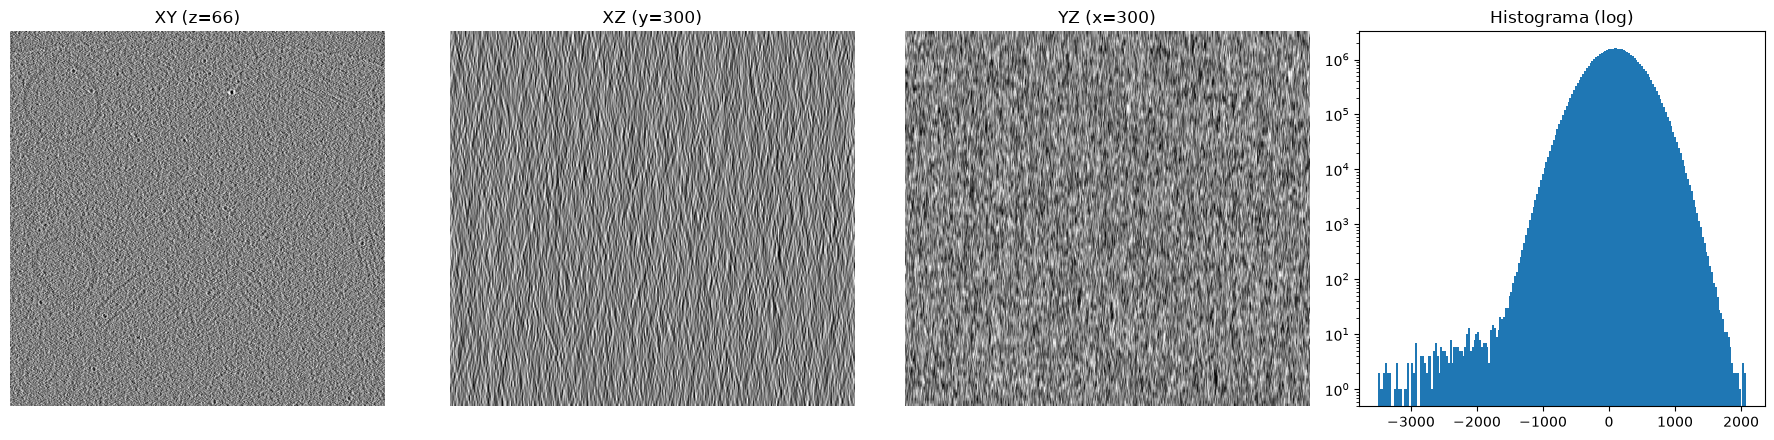

In [8]:
TOMO = DATASET_DIR / "sample_1_10490.mrc"     
OUT  = DATASET_DIR / "limpio"
OUT.mkdir(exist_ok=True)

crudo, voxel = leer_volumen(TOMO)
print(f"{TOMO.name}: shape={crudo.shape} (z,y,x)  dtype original->float32  vóxel={voxel} Å")
print(f"min={crudo.min():.4g}  max={crudo.max():.4g}  media={crudo.mean():.4g}  std={crudo.std():.4g}")
p1, p50, p99 = np.percentile(crudo, (1, 50, 99))
print(f"p1={p1:.4g}  mediana={p50:.4g}  p99={p99:.4g}")

zc, yc, xc = (n // 2 for n in crudo.shape)
fig, axs = plt.subplots(1, 4, figsize=(18, 4.5))
axs[0].imshow(crudo[zc], cmap="gray", vmin=p1, vmax=p99); axs[0].set_title(f"XY (z={zc})")
axs[1].imshow(crudo[:, yc, :], cmap="gray", vmin=p1, vmax=p99, aspect="auto"); axs[1].set_title(f"XZ (y={yc})")
axs[2].imshow(crudo[:, :, xc], cmap="gray", vmin=p1, vmax=p99, aspect="auto"); axs[2].set_title(f"YZ (x={xc})")
axs[3].hist(crudo.ravel(), bins=200, log=True); axs[3].set_title("Histograma (log)")
for a in axs[:3]: a.axis("off")
plt.tight_layout(); plt.show()

## 1.3 Técnica A: Topaz-Denoise 3D

Modelo 3D general preentrenado de Topaz (Bepler et al., 2020). No requiere entrenar ni datos pares/impares. El resultado se guarda como `.mrc` con el mismo tamaño de vóxel.

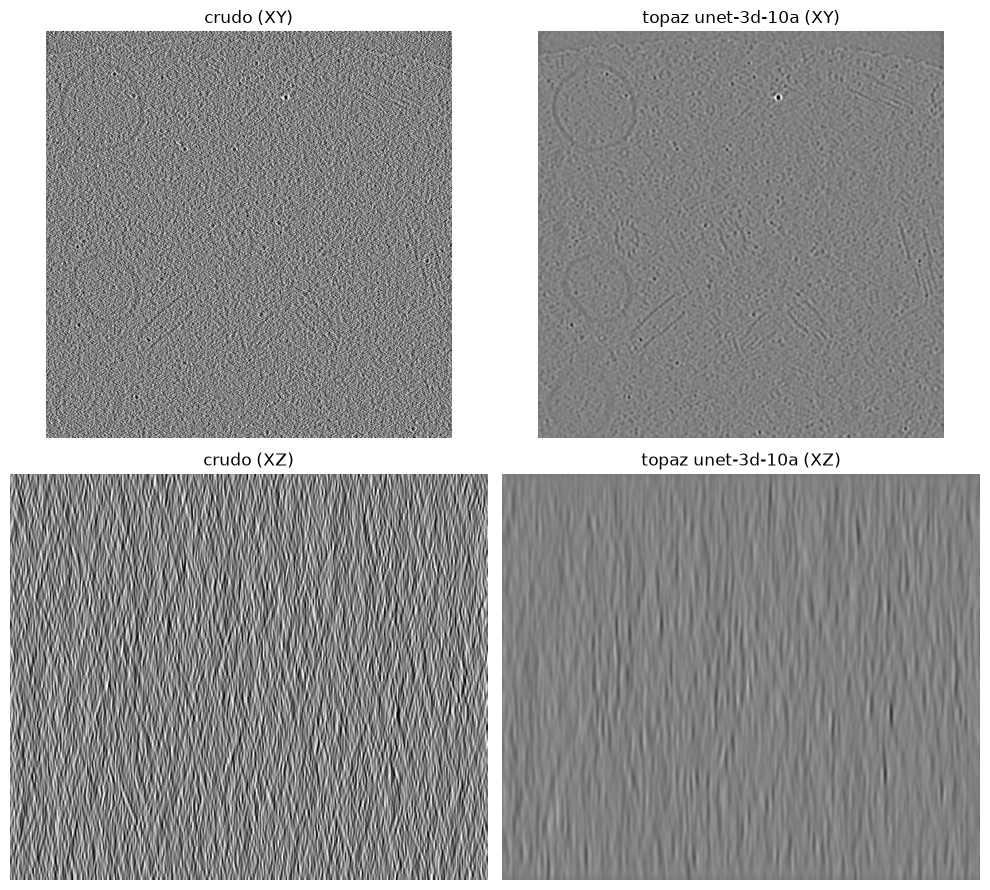

In [9]:
import napari

MODELO = "unet-3d-10a"

topaz_vol, _ = leer_volumen(OUT / "topaz" / f"{TOMO.stem}_entrada.mrc")
guardar_mrc(OUT / f"{TOMO.stem}_topaz_{MODELO}.mrc", topaz_vol, voxel)
comparar({"crudo": crudo, f"topaz {MODELO}": topaz_vol})

In [10]:


# Mismo contraste para los dos, para que la comparación sea justa
lo, hi = np.percentile(crudo, [1, 99])
escala = (voxel, voxel, voxel)   # (z, y, x) en Å

viewer = napari.Viewer(title="Crudo vs Topaz", ndisplay=2)
viewer.add_image(crudo, name="crudo", scale=escala,
                 contrast_limits=(lo, hi), colormap="gray")
viewer.add_image(topaz_vol, name=f"topaz {MODELO}", scale=escala,
                 contrast_limits=(lo, hi), colormap="gray")

# Los dos lado a lado, con los cortes sincronizados al mover el deslizador
viewer.grid.enabled = True
viewer.grid.shape = (1, 2)
viewer.scale_bar.visible = True
viewer.scale_bar.unit = "Å"

C:\Users\pauum\AppData\Local\Temp\ipykernel_73336\1228013694.py:15: FutureWarning: Setting unit on the ScaleBar model is deprecated and no longer has any effect. This attribute will be removed in 0.10.0.
Units are instead computed from the layers in the layerlist. Use `Layer.units` to set units for each layer.
  viewer.scale_bar.unit = "Å"


In [ ]:
# # ---- Técnica A: Topaz-Denoise 3D (modelo general preentrenado, sin entrenar) ----
# TOPAZ_EXE = r"C:\Users\pauum\envs\topaz\Scripts\topaz.exe"
# MODELO    = "unet-3d-10a" # preentrenados: unet-3d, unet-3d-10a, unet-3d-20a
# DEVICE    = -1            # -1 = CPU (lento), 0 = primera GPU
# GAUSS     = 0             # filtro gaussiano posterior (0 = ninguno)
# PATCH, PAD = 64, 16       # en CPU, parches pequeños; con GPU puedes subir a 96 y 48

# dest = OUT / "topaz"
# dest.mkdir(exist_ok=True)                     
# entrada = OUT / f"{TOMO.stem}_entrada.mrc"     
# guardar_mrc(entrada, crudo, voxel)

# cmd = [TOPAZ_EXE, "denoise3d", "-m", MODELO, "-d", str(DEVICE),
#        "-s", str(PATCH), "-p", str(PAD), "-g", str(GAUSS), "-o", str(dest), str(entrada)]
# print(" ".join(cmd))
# res = subprocess.run(cmd, capture_output=True, text=True)
# print(res.stdout[-2000:])
# print(res.stderr[-3000:])
# res.check_returncode()
# topaz_vol, _ = leer_volumen(dest / entrada.name)   # topaz guarda con el mismo nombre de archivo
# guardar_mrc(OUT / f"{TOMO.stem}_topaz_{MODELO}.mrc", topaz_vol, voxel)
# print(f"shape={topaz_vol.shape}  std crudo={crudo.std():.4g}  std limpio={topaz_vol.std():.4g}")
# comparar({"crudo": crudo, f"topaz {MODELO}": topaz_vol})

## 1.4 Técnica B: cryoCARE

Requiere dos tomogramas de la misma muestra reconstruidos con los frames pares e impares. Para el dataset 10490 no aplica debido a que solo tiene un tomograma

In [ ]:
# # ---- cryoCARE: necesita DOS tomogramas de la misma muestra (frames pares e impares) ----
# EVEN = None   # p. ej. Path("ruta/tomo_EVN.mrc")
# ODD  = None   # p. ej. Path("ruta/tomo_ODD.mrc")

# if EVEN is None or ODD is None:
#     print("cryoCARE se salta: este dataset solo tiene el tomograma final, sin pares/impares.")
# else:
#     d = OUT / "cryocare"; d.mkdir(exist_ok=True)
#     cfg_datos = {"even": [str(EVEN)], "odd": [str(ODD)], "patch_shape": [72, 72, 72], "num_slices": 1200,
#                  "split": 0.9, "tilt_axis": "Y", "n_normalization_samples": 500, "path": str(d)}
#     cfg_train = {"train_data": str(d), "epochs": 100, "steps_per_epoch": 200, "batch_size": 16,
#                  "unet_kern_size": 3, "unet_n_depth": 3, "unet_n_first": 16, "learning_rate": 0.0004,
#                  "model_name": "cryocare", "path": str(d), "gpu_id": 0}
#     cfg_pred  = {"path": str(d / "cryocare.tar.gz"), "even": str(EVEN), "odd": str(ODD),
#                  "n_tiles": [1, 1, 1], "output": str(d / "denoised.rec"), "overwrite": False, "gpu_id": 0}
#     for nombre, cfg in [("train_data_config", cfg_datos), ("train_config", cfg_train), ("predict_config", cfg_pred)]:
#         (d / f"{nombre}.json").write_text(json.dumps(cfg, indent=2))
#     print("Configs escritas en", d)
#     print("Ejecuta, en este orden, en el entorno de cryoCARE (Linux con GPU):")
#     for c in ["cryoCARE_extract_train_data.py --conf train_data_config.json",
#               "cryoCARE_train.py --conf train_config.json",
#               "cryoCARE_predict.py --conf predict_config.json"]:
#         print("  ", c)

## 1.5 Técnica C: IsoNet2

Red autosupervisada que corrige el missing wedge y reduce el ruido a la vez. IsoNet2 admite tomogramas completos (sin pares/impares), y en ese caso se usa `--method isonet2`. Necesita Linux con GPU, por lo que no se ha probado.

In [ ]:
# # ---- Técnica C: IsoNet2 (preparar entrada + script; se ejecuta en una máquina Linux con GPU) ----
# TILT_MIN, TILT_MAX = -60, 60     # rango de inclinación de la adquisición: AJÚSTALO (mira los metadatos del dataset)
# CUBE_SIZE, EPOCHS, GPU_ID = 96, 50, "0"

# ISO = OUT / "isonet"
# (ISO / "tomograms_full").mkdir(parents=True, exist_ok=True)
# guardar_mrc(ISO / "tomograms_full" / f"{TOMO.stem}.mrc", crudo, voxel)   # IsoNet lee el tomograma completo

# pixel = voxel if voxel else 6.8      # Å/vóxel; si el cargador no lo conoce, pon el valor real
# script = f"""#!/bin/bash
# # Ejecutar DENTRO de esta carpeta, en el entorno donde esté instalado IsoNet2 (Linux + GPU).
# # Los argumentos vienen de un ejemplo de uso de IsoNet2; compruébalos con `isonet.py <paso> -h`.
# set -e
# isonet.py prepare_star --full tomograms_full --pixel_size {pixel:.3f} --tilt_min {TILT_MIN} --tilt_max {TILT_MAX}
# # Opcional (máscara): isonet.py make_mask tomograms.star
# isonet.py refine tomograms.star --method isonet2 --cube_size {CUBE_SIZE} --epochs {EPOCHS} --gpuID {GPU_ID}
# """
# (ISO / "run_isonet.sh").write_text(script, newline="\n")
# print(script)
# print(f"Carpeta lista: {ISO.resolve()}")
# print("Llévala a la máquina con GPU, ejecuta `bash run_isonet.sh` y copia de vuelta la carpeta `isonet_maps/`.")

In [ ]:
# # ---- Recoger el resultado de IsoNet2 (ejecutar cuando exista la carpeta isonet_maps/) ----
# mapas = sorted((ISO / "isonet_maps").glob("*.mrc")) if (ISO / "isonet_maps").exists() else []
# if not mapas:
#     print(f"Aún no hay resultados en {ISO / 'isonet_maps'}. Ejecuta antes run_isonet.sh y copia esa carpeta aquí.")
# else:
#     print("Resultados encontrados:", [m.name for m in mapas])
#     iso_vol, _ = leer_volumen(mapas[-1])          # el más reciente; cambia el índice si hay varios
#     guardar_mrc(OUT / f"{TOMO.stem}_isonet2.mrc", iso_vol, voxel)
#     vols = {"crudo": crudo, "isonet2": iso_vol}
#     if "topaz_vol" in globals() and topaz_vol.shape == crudo.shape:
#         vols["topaz"] = topaz_vol
#     print(f"shape={iso_vol.shape}  std crudo={crudo.std():.4g}  std isonet2={iso_vol.std():.4g}")
#     comparar(vols)